In [1]:
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
import hashlib
import numpy as np
import matplotlib.pyplot as plt

username = "konda.rithvika"  
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed:", seed)

Seed: 2226785795


In [2]:
from sd import StudentDataset

# -------------------------------------------------
# Preprocess dataset (encode categorical X)
# -------------------------------------------------
def prepare_data(df):
    """
    Prepares the dataset for regression by separating features and target,
    and encoding categorical features using one-hot encoding.


    Args:
    df (pd.DataFrame): Input dataset containing features and the target column "GPA".


    Returns:
    X_enc (ndarray): One-hot encoded feature matrix.
    y (ndarray): Target variable (GPA).
    enc (OneHotEncoder): Fitted encoder for later use in feature naming.
    """
    X = df.drop(columns=["GPA"])
    y = df["GPA"].values

    # One-hot encode categorical features
    enc = OneHotEncoder(sparse_output=False)
    X_enc = enc.fit_transform(X)

    return X_enc, y, enc


# -------------------------------------------------
# Main regression function
# -------------------------------------------------
def run_poly_regression(X_train, y_train,
                        X_val, y_val,
                        X_test, y_test,
                        degree=1,
                        regularizer=None,
                        reg_strength=0.0):
    """
    Fits a polynomial regression model (optionally with L1 or L2 regularization)
    and evaluates it on train, validation, and test sets.
    Args:
    X_train (ndarray): Training feature matrix.
    y_train (ndarray): Training labels.
    X_val (ndarray): Validation feature matrix.
    y_val (ndarray): Validation labels.
    X_test (ndarray): Test feature matrix.
    y_test (ndarray): Test labels.
    degree (int, optional): Degree of polynomial features. Defaults to 1.
    regularizer (str, optional): Regularization type, one of {None, 'l1', 'l2'}.
    reg_strength (float, optional): Regularization strength (alpha). Defaults to 0.0.
    Returns:
    dict: Dictionary containing training, validation, and test MSE,
    along with fitted model coefficients.
    """
    # Expand polynomial features
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_val_poly = poly.transform(X_val)
    X_test_poly = poly.transform(X_test)

    # Choose model
    if regularizer is None:
        model = LinearRegression()
    elif regularizer == "l2":
        model = Ridge(alpha=reg_strength)
    elif regularizer == "l1":
        model = Lasso(alpha=reg_strength, max_iter=5000)
    else:
        raise ValueError("regularizer must be None, 'l1', or 'l2'")

    # Fit
    model.fit(X_train_poly, y_train)

    # Predictions
    y_pred_train = model.predict(X_train_poly)
    y_pred_val = model.predict(X_val_poly)
    y_pred_test = model.predict(X_test_poly)

    # MSE
    train_mse = mean_squared_error(y_train, y_pred_train)
    val_mse = mean_squared_error(y_val, y_pred_val)
    test_mse = mean_squared_error(y_test, y_pred_test)

    return {
        "train_mse": train_mse,
        "val_mse": val_mse,
        "test_mse": test_mse,
        "coefficients": model.coef_
    }



def experiment(dataset_df):
    """
    Runs a full experiment pipeline:
    1. Splits dataset into train, validation, and test sets.
    2. Trains polynomial regression models with different degrees.
    3. Evaluates performance with and without regularization (L1/L2).
    4. Tunes regularization strength (alpha) for L1 and L2.
    5. Plots validation curves for degree vs. MSE and alpha vs. MSE.
    6. Prints feature importance from the best model.
    Args:
    dataset_df (pd.DataFrame): Dataset containing categorical features and target column "GPA".
    Returns:
    None. (Prints results and generates plots.)
    """
    # Split dataset
    X, y, enc = prepare_data(dataset_df)
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=seed)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=seed)

    regularizers = [None, "l1", "l2"]
    reg_names = ["No Reg", "L1", "L2"]

    for reg, name in zip(regularizers, reg_names):
        print(f"\n===== {name} Regularization =====")

        # Step A: Degree vs MSE (default alpha=0.01 if regularized)
        train_mses, val_mses, test_mses = [], [], []
        degrees = range(1, 7)
        alpha = 0.01 if reg else 0.0

        print(f"\n{name} - Degree vs MSE (alpha={alpha}):")
        for d in degrees:
            res = run_poly_regression(X_train, y_train,
                                      X_val, y_val,
                                      X_test, y_test,
                                      degree=d,
                                      regularizer=reg,
                                      reg_strength=alpha)
            train_mses.append(res["train_mse"])
            val_mses.append(res["val_mse"])
            test_mses.append(res["test_mse"])
            print(f"Degree {d}: Train MSE = {res['train_mse']:.4f}, "
                  f"Val MSE = {res['val_mse']:.4f}, "
                  f"Test MSE = {res['test_mse']:.4f}")

        # Plot Degree vs MSE
        plt.figure(figsize=(6, 4))
        plt.plot(degrees, train_mses, marker="o", label="Train MSE")
        plt.plot(degrees, val_mses, marker="o", label="Val MSE")
        # plt.plot(degrees, test_mses, marker="o", label="Test MSE")
        plt.xlabel("Polynomial Degree")
        plt.ylabel("MSE")
        plt.title(f"Degree vs MSE ({name}, alpha={alpha})")
        plt.legend()
        plt.grid(True)
        plt.text(0.5, 0.5, 'Rithvika',
                    transform=plt.gcf().transFigure,
                    fontsize=40, color='gray', alpha=0.3,
                    ha='center', va='center', rotation=30)
        
        plt.show()

        # Step B: Find best degree (lowest val MSE)
        best_degree = degrees[np.argmin(val_mses)]
        print(f"\nBest degree for {name}: {best_degree}")

        # Step C: Tune regularization strength (only for L1/L2)
        if reg is not None:
            alphas = [10**i for i in range(-3, 3)]  # [0.001, 0.01, 0.1, 1, 10, 100]
            val_mses_alpha = []
            test_mses_alpha = []

            print(f"\n{name} - Tuning alpha at best degree {best_degree}:")
            for a in alphas:
                res = run_poly_regression(X_train, y_train,
                                          X_val, y_val,
                                          X_test, y_test,
                                          degree=best_degree,
                                          regularizer=reg,
                                          reg_strength=a)
                val_mses_alpha.append(res["val_mse"])
                test_mses_alpha.append(res["test_mse"])
                print(f"Alpha {a:.3f}: Val MSE = {res['val_mse']:.4f}, "
                      f"Test MSE = {res['test_mse']:.4f}")

            # Plot alpha vs val MSE
            plt.figure(figsize=(6, 4))
            plt.semilogx(alphas, val_mses_alpha, marker="o", label="Val MSE")
            # plt.semilogx(alphas, test_mses_alpha, marker="o", label="Test MSE")
            plt.xlabel("Regularization Strength (alpha, log scale)")
            plt.ylabel("MSE")
            plt.title(f"Alpha vs MSE ({name}, Degree={best_degree})")
            plt.grid(True, which="both", linestyle="--", linewidth=0.5)
            plt.text(0.5, 0.5, 'Rithvika',
                    transform=plt.gcf().transFigure,
                    fontsize=40, color='gray', alpha=0.3,
                    ha='center', va='center', rotation=30)
            plt.legend()
            plt.show()
            
               # -------------------------------
            # Feature importance calculation
            # -------------------------------
            print(f"\n{name} - Feature Importance (Top Features):")
            # Determine best alpha from tuning results (fallback to 0.01)
            try:
                best_alpha_idx = np.argmin(val_mses_alpha)
                best_alpha_val = alphas[best_alpha_idx]
            except Exception:
                best_alpha_val = 0.01

            print(f"Using alpha = {best_alpha_val} for final {name} model (degree={best_degree})")

            
            # Fit final model with best alpha and degree
            if reg == "l1":
                final_model = Lasso(alpha=0.01, max_iter=5000)
            else:  # L2
                # Choose alpha that gave lowest val MSE
                best_alpha_idx = np.argmin(val_mses_alpha)
                best_alpha_val = alphas[best_alpha_idx]
                final_model = Ridge(alpha=best_alpha_val)
            
            # Polynomial transform
            poly = PolynomialFeatures(degree=best_degree, include_bias=False)
            X_train_poly = poly.fit_transform(X_train)
            final_model.fit(X_train_poly, y_train)

            # Get feature names
            orig_features = enc.get_feature_names_out()
            poly_features = poly.get_feature_names_out(orig_features)
            coef = final_model.coef_
            non_zero_idx = np.where(coef != 0)[0]
            important_features = [(poly_features[i], coef[i]) for i in non_zero_idx]
            important_features = sorted(important_features, key=lambda x: abs(x[1]), reverse=True)

            # Print top 10 features
            for f, c in important_features[:10]:
                print(f"{f}: {c:.4f}")
                

            # Step D: Plot val MSE vs degree for specific alphas
            selected_alphas = [0.001, 0.01, 0.1, 10, 100]
            plt.figure(figsize=(7, 5))
            print(f"\n{name} - Val/Test MSE vs Degree for different alphas:")
            for a in selected_alphas:
                val_mses_by_degree = []
                test_mses_by_degree = []
                print(f"\nAlpha = {a}:")
                for d in degrees:
                    res = run_poly_regression(X_train, y_train,
                                              X_val, y_val,
                                              X_test, y_test,
                                              degree=d,
                                              regularizer=reg,
                                              reg_strength=a)
                    val_mses_by_degree.append(res["val_mse"])
                    test_mses_by_degree.append(res["test_mse"])
                    print(f"  Degree {d}: Val MSE = {res['val_mse']:.4f}, "
                          f"Test MSE = {res['test_mse']:.4f}")
                plt.plot(degrees, val_mses_by_degree, marker='o', label=f'Val MSE (alpha={a})')
                # plt.plot(degrees, test_mses_by_degree, marker='x', linestyle='--', label=f'Test MSE (alpha={a})')

            plt.xlabel("Polynomial Degree")
            plt.ylabel("MSE")
            plt.title(f"MSE vs Degree ({name})")
            plt.legend()
            plt.grid(True)
            plt.text(0.5, 0.5, 'Rithvika',
                    transform=plt.gcf().transFigure,
                    fontsize=40, color='gray', alpha=0.3,
                    ha='center', va='center', rotation=30)
            plt.show()





===== No Reg Regularization =====

No Reg - Degree vs MSE (alpha=0.0):
Degree 1: Train MSE = 0.8122, Val MSE = 0.8232, Test MSE = 0.7433
Degree 2: Train MSE = 0.8101, Val MSE = 0.8242, Test MSE = 0.7420
Degree 3: Train MSE = 0.8096, Val MSE = 0.8260, Test MSE = 0.7432
Degree 4: Train MSE = 0.8096, Val MSE = 0.8260, Test MSE = 0.7432
Degree 5: Train MSE = 0.8096, Val MSE = 0.8260, Test MSE = 0.7432
Degree 6: Train MSE = 0.8096, Val MSE = 0.8260, Test MSE = 0.7432


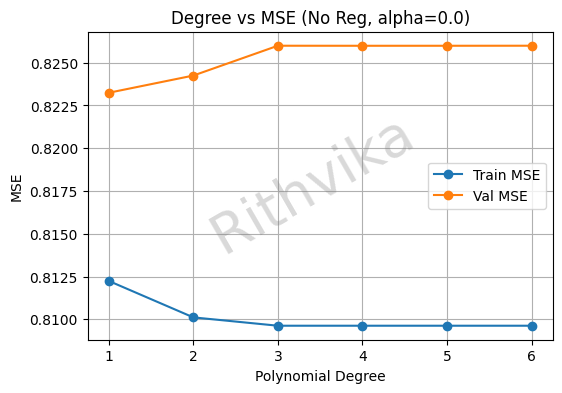


Best degree for No Reg: 1

===== L1 Regularization =====

L1 - Degree vs MSE (alpha=0.01):
Degree 1: Train MSE = 0.8143, Val MSE = 0.8218, Test MSE = 0.7424
Degree 2: Train MSE = 0.8138, Val MSE = 0.8218, Test MSE = 0.7418
Degree 3: Train MSE = 0.8138, Val MSE = 0.8218, Test MSE = 0.7418
Degree 4: Train MSE = 0.8138, Val MSE = 0.8218, Test MSE = 0.7418
Degree 5: Train MSE = 0.8138, Val MSE = 0.8218, Test MSE = 0.7418
Degree 6: Train MSE = 0.8138, Val MSE = 0.8218, Test MSE = 0.7418


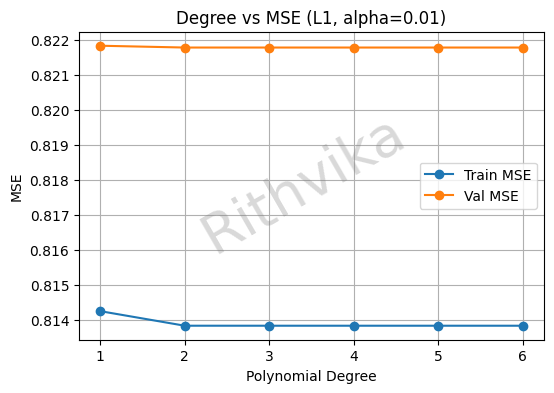


Best degree for L1: 2

L1 - Tuning alpha at best degree 2:
Alpha 0.001: Val MSE = 0.8227, Test MSE = 0.7432
Alpha 0.010: Val MSE = 0.8218, Test MSE = 0.7418
Alpha 0.100: Val MSE = 0.8612, Test MSE = 0.7827
Alpha 1.000: Val MSE = 1.0582, Test MSE = 0.9818
Alpha 10.000: Val MSE = 1.0582, Test MSE = 0.9818
Alpha 100.000: Val MSE = 1.0582, Test MSE = 0.9818


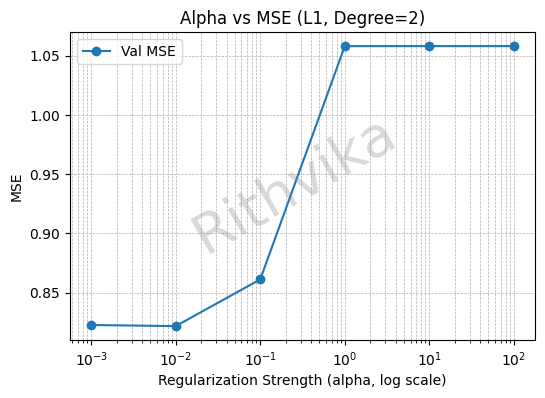


L1 - Feature Importance (Top Features):
Using alpha = 0.01 for final L1 model (degree=2)
Major_B.Tech: -0.9887
Major_PhD: 0.2230
Gender_Female Major_B.Tech: -0.0276
Major_B.Tech Program_ECE: -0.0084
Gender_Male Program_CSE: 0.0010

L1 - Val/Test MSE vs Degree for different alphas:

Alpha = 0.001:
  Degree 1: Val MSE = 0.8229, Test MSE = 0.7428
  Degree 2: Val MSE = 0.8227, Test MSE = 0.7432
  Degree 3: Val MSE = 0.8233, Test MSE = 0.7434
  Degree 4: Val MSE = 0.8233, Test MSE = 0.7434
  Degree 5: Val MSE = 0.8233, Test MSE = 0.7434
  Degree 6: Val MSE = 0.8233, Test MSE = 0.7434

Alpha = 0.01:
  Degree 1: Val MSE = 0.8218, Test MSE = 0.7424
  Degree 2: Val MSE = 0.8218, Test MSE = 0.7418
  Degree 3: Val MSE = 0.8218, Test MSE = 0.7418
  Degree 4: Val MSE = 0.8218, Test MSE = 0.7418
  Degree 5: Val MSE = 0.8218, Test MSE = 0.7418
  Degree 6: Val MSE = 0.8218, Test MSE = 0.7418

Alpha = 0.1:
  Degree 1: Val MSE = 0.8612, Test MSE = 0.7827
  Degree 2: Val MSE = 0.8612, Test MSE = 0.7827


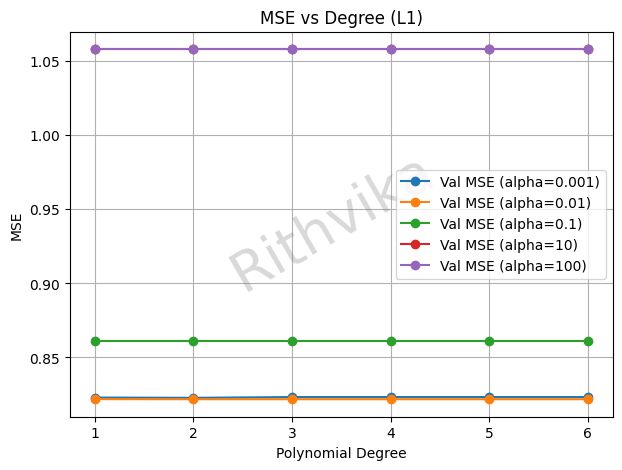


===== L2 Regularization =====

L2 - Degree vs MSE (alpha=0.01):
Degree 1: Train MSE = 0.8122, Val MSE = 0.8232, Test MSE = 0.7433
Degree 2: Train MSE = 0.8101, Val MSE = 0.8242, Test MSE = 0.7420
Degree 3: Train MSE = 0.8096, Val MSE = 0.8260, Test MSE = 0.7432
Degree 4: Train MSE = 0.8096, Val MSE = 0.8260, Test MSE = 0.7432
Degree 5: Train MSE = 0.8096, Val MSE = 0.8260, Test MSE = 0.7432
Degree 6: Train MSE = 0.8096, Val MSE = 0.8260, Test MSE = 0.7432


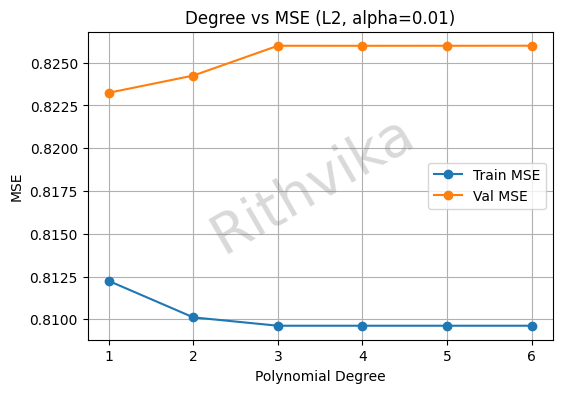


Best degree for L2: 1

L2 - Tuning alpha at best degree 1:
Alpha 0.001: Val MSE = 0.8232, Test MSE = 0.7433
Alpha 0.010: Val MSE = 0.8232, Test MSE = 0.7433
Alpha 0.100: Val MSE = 0.8232, Test MSE = 0.7433
Alpha 1.000: Val MSE = 0.8232, Test MSE = 0.7432
Alpha 10.000: Val MSE = 0.8231, Test MSE = 0.7431
Alpha 100.000: Val MSE = 0.8228, Test MSE = 0.7426


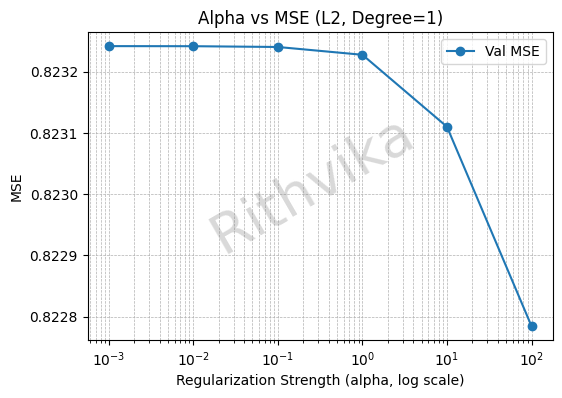


L2 - Feature Importance (Top Features):
Using alpha = 100 for final L2 model (degree=1)
Major_B.Tech: -0.7341
Major_PhD: 0.4951
Major_MS: 0.2390
Program_ECE: -0.0361
Program_CND: 0.0329
Gender_Female: -0.0243
Gender_Male: 0.0234
Program_CSE: 0.0097
Program_CHD: -0.0065
Gender_Other: 0.0009

L2 - Val/Test MSE vs Degree for different alphas:

Alpha = 0.001:
  Degree 1: Val MSE = 0.8232, Test MSE = 0.7433
  Degree 2: Val MSE = 0.8242, Test MSE = 0.7420
  Degree 3: Val MSE = 0.8260, Test MSE = 0.7432
  Degree 4: Val MSE = 0.8260, Test MSE = 0.7432
  Degree 5: Val MSE = 0.8260, Test MSE = 0.7432
  Degree 6: Val MSE = 0.8260, Test MSE = 0.7432

Alpha = 0.01:
  Degree 1: Val MSE = 0.8232, Test MSE = 0.7433
  Degree 2: Val MSE = 0.8242, Test MSE = 0.7420
  Degree 3: Val MSE = 0.8260, Test MSE = 0.7432
  Degree 4: Val MSE = 0.8260, Test MSE = 0.7432
  Degree 5: Val MSE = 0.8260, Test MSE = 0.7432
  Degree 6: Val MSE = 0.8260, Test MSE = 0.7432

Alpha = 0.1:
  Degree 1: Val MSE = 0.8232, Test M

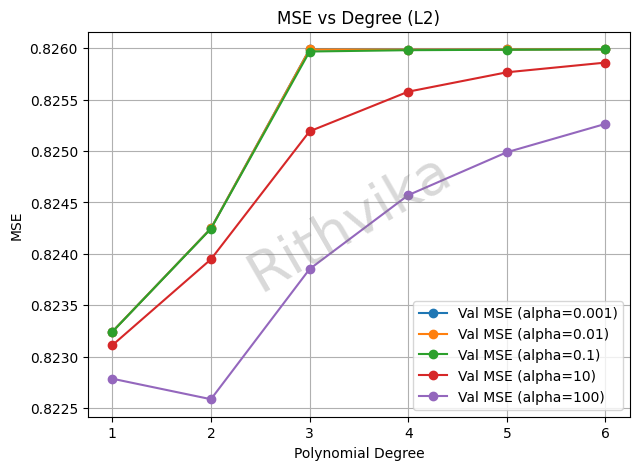

In [3]:

# Generate a dataset
student_data = StudentDataset(num_students=10000, seed=seed).get_full_dataframe()

# Run experiments
experiment(student_data)


## a) Observations and Trend Analysis

### 1. No Regularization
**Observation:**
- Train MSE decreases slightly with higher degree (from 0.8122 → 0.8096), but Validation MSE increases slightly or stays constant.
- No significant overfitting, likely because the dataset is small and features are categorical (one-hot encoded).
- Test MSE is fairly stable.

**Best Degree:** 1 (lowest validation MSE)

---

### 2. L1 Regularization
**Observation:**
- MSE values are very close across degrees.
- L1 regularization slightly increases train MSE but slightly improves Validation and Test MSE.
- Best degree chosen based on validation: **Degree 2**.

**Alpha Tuning (best degree = 2):**
- Very small alpha (0.01) works best.
- Large alpha → underfitting (MSE increases significantly).

---

### 3. L2 Regularization
**Observation:**
- Very similar to no regularization. L2 does not make a noticeable difference.
- Best degree: **1**.

**Alpha Tuning (best degree = 1):**
- L2 slightly reduces validation/test MSE at very large alpha, but the overall effect is minor.


## b) Performance Improvement from Regularization

Comparing the three setups—**No Regularization**, **L1**, and **L2**—we can observe the following trends:

#### L1 Regularization
- Slightly reduces both validation and test MSE compared to no regularization, particularly for polynomial degree 2.
- Helps by shrinking less important coefficients to zero, effectively performing feature selection.

#### L2 Regularization
- Shows minimal improvement over the unregularized model.
- Coefficients are slightly shrunk, but all features remain in the model.
- Best performance occurs at degree 1 with large alpha, yet the overall effect is small.

#### No Regularization
- Performs reasonably well, but slightly higher MSE than the optimal L1 setup.
- Increasing polynomial degree does not significantly reduce MSE and may slightly increase validation error, indicating minor overfitting at higher degrees.

### Conclusion
Regularization is not crucial for this dataset because:
- Most features are categorical and one-hot encoded, reducing the risk of overfitting.
- The feature set is small, limiting model complexity.

### Best Overall Configuration
- **Regularization:** L1  
- **Polynomial Degree:** 2  
- **Alpha:** 0.01  
- **Achieved Test MSE:** 0.7418 (slightly better than other setups)

### Interpretation
- **L1** helps by identifying the most influential predictors for GPA while removing irrelevant features.  
- **L2** offers modest improvement but does not simplify the model.


#### c) Feature Analysis

### 1. L1 Regularization (Best Setup: Degree 2, α = 0.01)
L1 regularization (Lasso) tends to shrink less important coefficients to exactly zero, effectively performing feature selection.  
The non-zero coefficients represent the most influential predictors for GPA.

**Top Features and Coefficients:**

| Feature                        | Coefficient |
|--------------------------------|------------|
| Major_B.Tech                   | -0.9887    |
| Major_PhD                      | 0.2230     |
| Gender_Female Major_B.Tech     | -0.0276    |
| Major_B.Tech Program_ECE       | -0.0084    |
| Gender_Male Program_CSE        | 0.0010     |

## Observations

- The **Major** of the student is the most important predictor:  
  - Being a **B.Tech** student reduces predicted GPA.  
  - Being a **PhD** student increases predicted GPA.
- Some interaction terms (e.g., **Gender × Major**, **Major × Program**) have very small effects.
- Most coefficients for less relevant features are zero, simplifying the model.



### 2. L2 Regularization (Best Setup: Degree 1, α ≈ 100)

L2 regularization (Ridge) shrinks coefficients but does not set them to zero, so all features remain in the model.  
Coefficient magnitudes indicate relative importance.

**Top Features and Coefficients:**

| Feature           | Coefficient |
|------------------|------------|
| Major_B.Tech      | -0.7341    |
| Major_PhD         | 0.4951     |
| Major_MS          | 0.2390     |
| Program_ECE       | -0.0361    |
| Program_CND       | 0.0329     |
| Gender_Female     | -0.0243    |
| Gender_Male       | 0.0234     |
| Program_CSE       | 0.0097     |
| Program_CHD       | -0.0065    |
| Gender_Other      | 0.0009     |



**Observations:**
- Major remains the most influential predictor, similar to L1.
- L2 retains all features, including less relevant ones like Gender and Program, but their coefficients are very small.
- Coefficients are generally smaller in magnitude compared to L1, due to shrinkage.

### Conclusion:

- L1 helps identify the key predictors for GPA, making the model simpler and more interpretable.

- L2 spreads the influence across all features, which is useful if we believe all features contribute slightly but does not remove irrelevant predictors.

- For this dataset, Major is the dominant factor affecting GPA, regardless of regularization type.
